# 1. Pengaturan dan pemuatan data
Semua parameter eksperimen dikumpulkan pada satu sel agar mudah diubah. Nilai SAMPLE_SIZE dan N_ITER_SEARCH dapat dinaikkan apabila waktu komputasi memungkinkan.

In [1]:
import sys
import warnings
from pathlib import Path
import gc

# Agar paket `scripts` dapat diimpor dari folder notebooks/ (path absolut agar aman untuk proses paralel).
sys.path.append(str(Path("..").resolve()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.inspection import permutation_importance
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import RandomizedSearchCV, train_test_split

from scripts.preprocess import load_raw_data, split_features_target
from scripts.train import (DECISION_WEIGHTS_FILE, MODEL_SPECS, SEED, apply_class_weights,
                           evaluate_cv, get_cv, list_models, load_model, make_model,
                           save_decision_weights, save_params, train_and_save,
                           tune_class_weights)

DATA_DIR = Path("../data")
MODELS_DIR = Path("../models")
REPORT_DIR = Path("../reports")
FIG_DIR = REPORT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

N_SPLITS = 5              # jumlah fold validasi silang
HOLDOUT_FRACTION = 0.20   # porsi data latih yang disisihkan untuk evaluasi akhir
SAMPLE_SIZE = 50_000      # ukuran subsampel untuk perbandingan model dan tuning
N_ITER_SEARCH = 10        # jumlah kombinasi hiperparameter yang dicoba
CV_JOBS = -1              # paralelisasi antar-fold (-1 = seluruh inti CPU)

GRADE_COLORS = ["#fee391", "#fec44f", "#fe9929", "#d95f0e", "#993404"]
sns.set_theme(style="white", context="notebook")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 110, "axes.titleweight": "bold",
                     "axes.titlesize": 11, "axes.labelsize": 10})
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)


def save_fig(name: str) -> None:
    """Simpan figure aktif ke ``reports/figures/<name>.png`` (150 dpi).
    Args:
        name: Nama file tanpa ekstensi.
    """
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


train, _ = load_raw_data(DATA_DIR)
X, y = split_features_target(train)
print(f"Data latih: {X.shape[0]:,} baris x {X.shape[1]} kolom")

Data latih: 533,465 baris x 16 kolom


# 2. Pembagian data
Data latih dibagi menjadi tiga bagian dengan peran berbeda:

| Bagian | Fungsi |
|---|---|
| **Hold-out** (20%) | Disisihkan sejak awal dan **tidak disentuh** selama pemilihan model. Hanya dipakai satu kali untuk estimasi performa akhir. |
| **Subsampel pengembangan** | Diambil dari 80% sisanya; dipakai untuk validasi silang, ablation, dan penyetelan hiperparameter. |
| **Seluruh data latih** | Dipakai untuk pelatihan model akhir yang disimpan. |

Pemisahan ini mencegah *selection bias*: apabila model dipilih dan dievaluasi pada data yang sama, skor yang dilaporkan cenderung terlalu optimistis. Seluruh pembagian bersifat **berstrata** terhadap `damage_grade` agar proporsi kelas tetap terjaga.

*Catatan:* karena terdapat baris duplikat fitur (lihat notebook 01), sebagian baris pada hold-out memiliki kembaran pada data latih sehingga skor hold-out tetap dapat sedikit lebih optimistis daripada skor pada data uji Kaggle.

In [2]:
X_fit, X_hold, y_fit, y_hold = train_test_split(
    X, y, test_size=HOLDOUT_FRACTION, stratify=y, random_state=SEED)

if len(X_fit) > SAMPLE_SIZE:
    X_dev, _, y_dev, _ = train_test_split(
        X_fit, y_fit, train_size=SAMPLE_SIZE, stratify=y_fit, random_state=SEED)
else:
    X_dev, y_dev = X_fit, y_fit

display(pd.DataFrame(
    {"jumlah_baris": [len(X), len(X_fit), len(X_dev), len(X_hold)]},
    index=["Seluruh data latih", "Bagian latih (80%)",
           "Subsampel pengembangan", "Hold-out (evaluasi akhir)"]))

# Proporsi kelas harus hampir identik di semua bagian (bukti stratifikasi berhasil)
proporsi = pd.concat({"bagian latih": y_fit.value_counts(normalize=True),
                      "pengembangan": y_dev.value_counts(normalize=True),
                      "hold-out": y_hold.value_counts(normalize=True)}, axis=1).sort_index()
display(proporsi.style.format("{:.1%}"))

,jumlah_baris
Seluruh data latih,533465
Bagian latih (80%),426772
Subsampel pengembangan,50000
Hold-out (evaluasi akhir),106693


,bagian latih,pengembangan,hold-out
damage_grade,,,
Grade 1,10.3%,10.3%,10.3%
Grade 2,11.4%,11.5%,11.4%
Grade 3,17.9%,17.9%,17.9%
Grade 4,24.1%,24.1%,24.1%
Grade 5,36.2%,36.2%,36.2%


# 3. Baseline: prediksi kelas mayoritas
Seluruh model harus melampaui baseline sederhana, yaitu memprediksi kelas terbanyak untuk semua bangunan. Pada notebook 01 telah ditunjukkan bahwa baseline ini menghasilkan akurasi yang tampak wajar namun Macro F1 yang sangat rendah.

In [3]:
LABELS = sorted(y.unique())
majority_class = y_fit.mode()[0]
baseline_f1 = f1_score(y_hold, np.full(len(y_hold), majority_class),
                       average="macro", labels=LABELS, zero_division=0)
print(f"Kelas mayoritas        : {majority_class}")
print(f"Macro F1 baseline      : {baseline_f1:.3f}  (batas bawah yang harus dilampaui model)")

Kelas mayoritas        : Grade 5
Macro F1 baseline      : 0.106  (batas bawah yang harus dilampaui model)


# 4. Perbandingan algoritma dengan validasi silang
Lima kandidat dibandingkan dengan `StratifiedKFold` yang sama sehingga perbandingannya adil. Daftar lengkap dan konfigurasinya berada pada `MODEL_SPECS` di `scripts/train.py`.

| Kandidat | Preprocessing | Keterangan |
|---|---|---|
| Logistic Regression (multinomial) | One-Hot + standardisasi | Baseline linear; satu model untuk seluruh kelas. |
| Logistic Regression (One-vs-Rest) | One-Hot + standardisasi | Satu pengklasifikasi biner per kelas (5 model). |
| Logistic Regression (One-vs-One) | One-Hot + standardisasi | Satu pengklasifikasi biner per pasangan kelas (10 model). |
| Random Forest | Ordinal | *Ensemble* pohon dengan *bagging*. |
| HistGradientBoosting | Ordinal | *Gradient boosting* berbasis histogram. |

Kapasitas Random Forest dibatasi secara proporsional terhadap jumlah data (`min_samples_leaf` diberikan sebagai fraksi), sehingga ukuran berkas model tetap wajar (sekitar puluhan MB) ketika dilatih pada seluruh data. Tanpa pembatasan, ukuran model dapat mencapai lebih dari 1 GB sehingga tidak dapat disimpan di GitHub maupun dimuat ulang pada komputer biasa.

Semua model memakai bobot kelas seimbang (`class_weight="balanced"`) untuk menyesuaikan ketimpangan kelas terhadap Macro F1. Model linear mungkin menampilkan `ConvergenceWarning`; peringatan ini tidak menghentikan proses, tetapi menandakan bahwa `max_iter` yang lebih besar dapat memperbaiki konvergensi.

In [4]:
cv = get_cv(N_SPLITS)
cv_results = {}
rows = []
for name in list_models():
    result = evaluate_cv(make_model(name), X_dev, y_dev, cv=cv, n_jobs=CV_JOBS)
    cv_results[name] = result
    rows.append({"model": name, "algoritma": MODEL_SPECS[name].label,
                 "macro_f1_mean": result["macro_f1_mean"], "macro_f1_std": result["macro_f1_std"],
                 "accuracy_mean": result["accuracy_mean"], "fit_seconds_mean": result["fit_seconds_mean"]})
    print(f"{name:<14} Macro F1 = {result['macro_f1_mean']:.4f} (± {result['macro_f1_std']:.4f})")

results = pd.DataFrame(rows).set_index("model").sort_values("macro_f1_mean", ascending=False)
results.to_csv(REPORT_DIR / "model_comparison.csv")
display(results.style.format({"macro_f1_mean": "{:.4f}", "macro_f1_std": "{:.4f}",
                              "accuracy_mean": "{:.3f}", "fit_seconds_mean": "{:.1f}"}))

reglog         Macro F1 = 0.4507 (± 0.0038)
reglog_ovr     Macro F1 = 0.4451 (± 0.0043)
reglog_ovo     Macro F1 = 0.4498 (± 0.0032)
random_forest  Macro F1 = 0.4784 (± 0.0015)
hist_gb_nbr    Macro F1 = 0.5128 (± 0.0060)
hist_gb        Macro F1 = 0.4696 (± 0.0056)


,algoritma,macro_f1_mean,macro_f1_std,accuracy_mean,fit_seconds_mean
model,,,,,
hist_gb_nbr,HistGradientBoosting + fitur tetangga ID,0.5128,0.0060,0.542,18.0
random_forest,Random Forest,0.4784,0.0015,0.520,8.9
hist_gb,HistGradientBoosting,0.4696,0.0056,0.508,7.9
reglog,Logistic Regression (multinomial),0.4507,0.0038,0.491,5.9
reglog_ovo,Logistic Regression (One-vs-One),0.4498,0.0032,0.491,2.9
reglog_ovr,Logistic Regression (One-vs-Rest),0.4451,0.0043,0.495,4.9


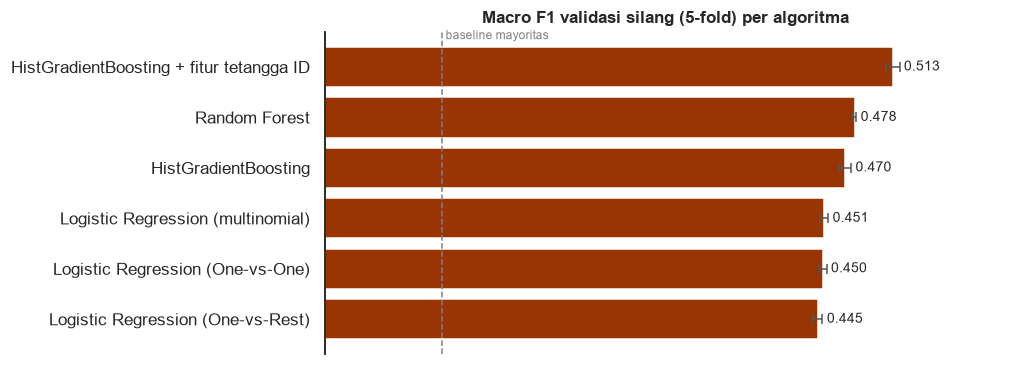

Model terbaik berdasarkan rata-rata Macro F1: HistGradientBoosting + fitur tetangga ID (hist_gb_nbr)
Model yang selisihnya masih dalam satu simpangan baku dari yang terbaik: ['hist_gb_nbr']


In [5]:
plot_df = results.sort_values("macro_f1_mean")
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(plot_df["algoritma"], plot_df["macro_f1_mean"], xerr=plot_df["macro_f1_std"],
        color="#993404", error_kw={"ecolor": "#555555", "lw": 1, "capsize": 3})
ax.axvline(baseline_f1, color="gray", ls="--", lw=1)
ax.text(baseline_f1 + 0.003, len(plot_df) - 0.45, "baseline mayoritas", color="gray", fontsize=8)
for i, (v, s) in enumerate(zip(plot_df["macro_f1_mean"], plot_df["macro_f1_std"])):
    ax.text(v + s + 0.004, i, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlim(0, plot_df["macro_f1_mean"].max() * 1.2)
ax.set_xticks([])
ax.spines["bottom"].set_visible(False)
ax.set_title(f"Macro F1 validasi silang ({N_SPLITS}-fold) per algoritma")
save_fig("07_model_comparison")
plt.show()

best_name = results.index[0]
best = results.iloc[0]
setara = results[results["macro_f1_mean"] >= best["macro_f1_mean"] - best["macro_f1_std"]]
print(f"Model terbaik berdasarkan rata-rata Macro F1: {MODEL_SPECS[best_name].label} ({best_name})")
print(f"Model yang selisihnya masih dalam satu simpangan baku dari yang terbaik: {list(setara.index)}")

Bar Chart menunjukkan rata-rata Macro F1 pada seluruh *fold*, dan garis galat menunjukkan simpangan baku antar-*fold*. Selisih antar-model yang lebih kecil daripada simpangan baku tidak dapat dianggap bermakna secara praktis. Pada kasus tersebut, model yang lebih sederhana dan lebih cepat dilatih layak dipertimbangkan, karena lebih mudah dijelaskan dan lebih murah dijalankan ulang.

Sel di atas memilih model terbaik secara otomatis (`best_name`) dari rata-rata Macro F1, dan seluruh sel berikutnya mengikuti pilihan tersebut. Apabila model yang dianggap setara memiliki keunggulan lain, nilai `best_name` dapat diganti secara manual.

# 5. Ablation study: manfaat fitur turunan
Fitur turunan (`n_rc_elements`, `n_mud_elements`, `area_per_floor`, dan lainnya) dirancang berdasarkan temuan EDA, tetapi manfaatnya terhadap performa belum terbukti. Pengujian dilakukan dengan membandingkan pipeline **dengan** dan **tanpa** fitur turunan (`use_engineered=False`) pada *fold* yang sama, sehingga selisih dapat dihitung secara berpasangan. Pengujian dilakukan pada model linear (`reglog`), model *boosting* (`hist_gb`), dan model terbaik hasil bagian 4, karena manfaat fitur turunan dapat berbeda antar-keluarga algoritma.

Perlu dicatat bahwa `n_rc_elements` dan `n_mud_elements` merupakan penjumlahan kolom kategorik yang sudah tersedia, sehingga untuk model linear dengan One-Hot Encoding keduanya tidak menambah informasi baru. Fitur lain (rasio per lantai, logaritma luas dasar, dan penanda umur tidak diketahui) bersifat non-linear atau menangani nilai khusus, sehingga tetap dapat memberi manfaat bagi model linear. Ablation ini tidak memisahkan kontribusi masing-masing fitur turunan.

In [6]:
ablation_rows = []
for name in dict.fromkeys(["reglog", "hist_gb", best_name]):  # model terbaik ikut diuji
    with_fe = cv_results[name]
    without_fe = evaluate_cv(make_model(name, use_engineered=False), X_dev, y_dev, cv=cv, n_jobs=CV_JOBS)
    diff = np.array(with_fe["fold_scores"]) - np.array(without_fe["fold_scores"])
    ablation_rows.append({
        "model": MODEL_SPECS[name].label,
        "tanpa_fitur_turunan": without_fe["macro_f1_mean"],
        "dengan_fitur_turunan": with_fe["macro_f1_mean"],
        "selisih_rata2": diff.mean(),
        "simpangan_baku_selisih": diff.std(),
        "fold_membaik": f"{int((diff > 0).sum())} dari {len(diff)}",
    })
ablation = pd.DataFrame(ablation_rows).set_index("model")
display(ablation.style.format({"tanpa_fitur_turunan": "{:.4f}", "dengan_fitur_turunan": "{:.4f}",
                               "selisih_rata2": "{:+.4f}", "simpangan_baku_selisih": "{:.4f}"}))

,tanpa_fitur_turunan,dengan_fitur_turunan,selisih_rata2,simpangan_baku_selisih,fold_membaik
model,,,,,
Logistic Regression (multinomial),0.4492,0.4507,+0.0015,0.0011,5 dari 5
HistGradientBoosting,0.4697,0.4696,-0.0001,0.0046,2 dari 5
HistGradientBoosting + fitur tetangga ID,0.5137,0.5128,-0.0009,0.0039,1 dari 5


Fitur turunan dianggap bermanfaat apabila selisih rata-rata bernilai positif, lebih besar daripada simpangan baku selisih, dan sebagian besar *fold* membaik. Apabila tidak terpenuhi, fitur turunan tidak memberikan peningkatan yang dapat dibuktikan; keputusan mempertahankan atau membuangnya kemudian bergantung pada pertimbangan kesederhanaan model. Pengujian pada data yang lebih besar (naikkan `SAMPLE_SIZE`) dapat menghasilkan kesimpulan yang lebih tegas.

# 6. Penyetelan hiperparameter
Hiperparameter model terbaik disetel menggunakan `RandomizedSearchCV` dengan ruang pencarian yang didefinisikan pada `MODEL_SPECS[...].search_space`. Pencarian acak dipilih karena lebih efisien daripada *grid search* pada ruang parameter yang luas, dan menggunakan 3-*fold* untuk menghemat waktu.

Hasil terbaik kemudian **dievaluasi ulang dengan 5-*fold* yang sama** seperti perbandingan awal, sehingga dapat dibandingkan secara adil dengan konfigurasi bawaan. Parameter hasil penyetelan hanya dipakai apabila benar-benar lebih baik daripada konfigurasi bawaan.

In [7]:
search = RandomizedSearchCV(
    make_model(best_name), param_distributions=MODEL_SPECS[best_name].search_space,
    n_iter=N_ITER_SEARCH, scoring="f1_macro", cv=get_cv(3), random_state=SEED,
    n_jobs=CV_JOBS, refit=False, error_score="raise")
search.fit(X_dev, y_dev)

search_table = (pd.DataFrame(search.cv_results_)[["params", "mean_test_score", "std_test_score"]]
                .sort_values("mean_test_score", ascending=False).reset_index(drop=True))
display(search_table.head(5))

tuned_result = evaluate_cv(make_model(best_name).set_params(**search.best_params_),
                           X_dev, y_dev, cv=cv, n_jobs=CV_JOBS)
default_result = cv_results[best_name]
use_tuned = tuned_result["macro_f1_mean"] > default_result["macro_f1_mean"]

print(f"Macro F1 5-fold, konfigurasi bawaan : {default_result['macro_f1_mean']:.4f}")
print(f"Macro F1 5-fold, hasil penyetelan   : {tuned_result['macro_f1_mean']:.4f}")
print(f"Parameter yang dipakai              : {'hasil penyetelan' if use_tuned else 'konfigurasi bawaan'}")

final_params = dict(search.best_params_) if use_tuned else {}
chosen_result = tuned_result if use_tuned else default_result
print("Hiperparameter akhir:", final_params or "(bawaan)")
save_params(MODELS_DIR / "best_params.json", best_name, final_params,
            cv_macro_f1=chosen_result["macro_f1_mean"])

,params,mean_test_score,std_test_score
0,"{'model__l2_regularization': 0.11400863701127326, 'model__learning_rate': 0.09230320822645494, 'model__max_leaf_node...",0.506741,0.000898
1,"{'model__l2_regularization': 0.5262961031076743, 'model__learning_rate': 0.0705166262783807, 'model__max_leaf_nodes'...",0.506043,0.002839
2,"{'model__l2_regularization': 0.014618962793704957, 'model__learning_rate': 0.0957705988053993, 'model__max_leaf_node...",0.505986,0.003760
3,"{'model__l2_regularization': 0.40137830238462535, 'model__learning_rate': 0.033388679840855015, 'model__max_leaf_nod...",0.505812,0.003131
4,"{'model__l2_regularization': 0.24810409748678125, 'model__learning_rate': 0.040333543290320795, 'model__max_leaf_nod...",0.505510,0.003190


Macro F1 5-fold, konfigurasi bawaan : 0.5128
Macro F1 5-fold, hasil penyetelan   : 0.5112
Parameter yang dipakai              : konfigurasi bawaan
Hiperparameter akhir: (bawaan)


WindowsPath('../models/best_params.json')

Apabila peningkatan akibat penyetelan sangat kecil, hal tersebut menunjukkan bahwa konfigurasi bawaan sudah mendekati optimum untuk data ini, dan peningkatan performa lebih lanjut kemungkinan harus berasal dari perbaikan fitur atau strategi pemodelan, bukan dari hiperparameter. Perlu diperhatikan juga apakah parameter terbaik berada pada **batas** ruang pencarian (misalnya nilai terbesar atau terkecil yang ditawarkan). Apabila ya, ruang tersebut kemungkinan membatasi hasil dan dapat diperluas, dengan tetap mempertimbangkan ukuran berkas model. Selisih skor antar-kombinasi yang lebih kecil daripada simpangan bakunya tidak dapat dianggap bermakna, pada kasus tersebut kombinasi yang lebih kecil dan lebih cepat layak dipilih.

Berkas `models/best_params.json` menyimpan konfigurasi akhir agar dapat dipakai langsung oleh `scripts/train.py`.

# 7. Evaluasi pada data hold-out
Model terpilih dilatih pada 80% data latih (`X_fit`), kemudian diuji **satu kali** pada data hold-out. Hasil ini merupakan estimasi performa yang paling jujur pada tahap eksperimen, karena data hold-out tidak digunakan untuk memilih model maupun hiperparameter.

In [8]:
holdout_model = make_model(best_name, n_jobs=-1).set_params(**final_params)
holdout_model.fit(X_fit, y_fit)
y_pred = holdout_model.predict(X_hold)

holdout_f1 = f1_score(y_hold, y_pred, average="macro")
labels = list(holdout_model.classes_)
print(f"Macro F1 hold-out : {holdout_f1:.4f}   (baseline mayoritas: {baseline_f1:.3f})")
print()
print(classification_report(y_hold, y_pred, labels=labels, digits=3))

# Proporsi kesalahan yang hanya selisih satu tingkat grade (relevan karena target ordinal)
order = {g: i for i, g in enumerate(labels)}
gap = np.abs(y_hold.map(order).to_numpy() - pd.Series(y_pred).map(order).to_numpy())
adjacent_share = (gap[gap > 0] == 1).mean()
print(f"Dari seluruh kesalahan prediksi, {adjacent_share:.1%} hanya berselisih satu tingkat grade.")

Macro F1 hold-out : 0.5758   (baseline mayoritas: 0.106)

              precision    recall  f1-score   support

     Grade 1      0.610     0.769     0.680     11034
     Grade 2      0.395     0.495     0.439     12216
     Grade 3      0.458     0.457     0.458     19098
     Grade 4      0.554     0.552     0.553     25738
     Grade 5      0.816     0.693     0.749     38607

    accuracy                          0.602    106693
   macro avg      0.567     0.593     0.576    106693
weighted avg      0.619     0.602     0.607    106693

Dari seluruh kesalahan prediksi, 71.9% hanya berselisih satu tingkat grade.


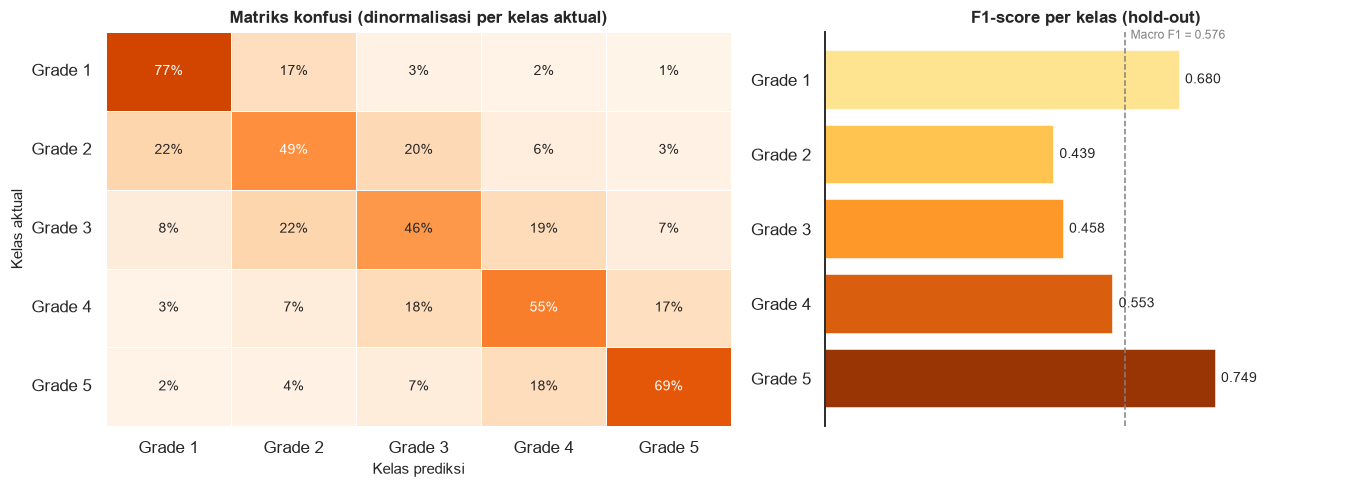

In [9]:
cm = confusion_matrix(y_hold, y_pred, labels=labels, normalize="true")
per_class_f1 = f1_score(y_hold, y_pred, average=None, labels=labels)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), gridspec_kw={"width_ratios": [1.2, 1]})
sns.heatmap(cm, annot=True, fmt=".0%", cmap="Oranges", vmin=0, vmax=1, cbar=False,
            xticklabels=labels, yticklabels=labels, linewidths=0.5, linecolor="white",
            ax=axes[0], annot_kws={"size": 9})
axes[0].tick_params(axis="y", rotation=0)
axes[0].set_xlabel("Kelas prediksi")
axes[0].set_ylabel("Kelas aktual")
axes[0].set_title("Matriks konfusi (dinormalisasi per kelas aktual)")

axes[1].barh(labels[::-1], per_class_f1[::-1], color=GRADE_COLORS[::-1])
axes[1].axvline(holdout_f1, color="gray", ls="--", lw=1)
axes[1].text(holdout_f1 + 0.01, len(labels) - 0.45, f"Macro F1 = {holdout_f1:.3f}", color="gray", fontsize=8)
for i, v in enumerate(per_class_f1[::-1]):
    axes[1].text(v + 0.01, i, f"{v:.3f}", va="center", fontsize=9)
axes[1].set_xlim(0, 1)
axes[1].set_xticks([])
axes[1].spines["bottom"].set_visible(False)
axes[1].set_title("F1-score per kelas (hold-out)")
fig.tight_layout()
save_fig("08_confusion_matrix_holdout")
plt.show()

Matriks konfusi dibaca per baris (kelas aktual); angka diagonal menunjukkan persentase bangunan yang diprediksi dengan benar, sedangkan angka di luar diagonal menunjukkan arah kesalahan. Karena damage_grade bersifat ordinal, kesalahan antar-grade bersebelahan secara substantif lebih ringan daripada kesalahan yang melompat jauh (misalnya Grade 1 diprediksi sebagai Grade 5); proporsi kesalahan bersebelahan dicetak pada sel sebelumnya. Kelas dengan F1 terendah menjadi prioritas perbaikan, karena Macro F1 memberi bobot yang sama pada setiap kelas.

## 7.1 Aturan keputusan untuk Macro F1
`argmax` pada probabilitas bukan pengoptimal Macro F1: kelas yang rawan tertukar dengan tetangganya (Grade 2 dan 3) perlu sedikit "dibantu". Aturan keputusan yang dipakai adalah `argmax(probabilitas × bobot)`, dengan satu pengali per kelas yang disetel agar Macro F1 maksimum (`tune_class_weights`). Karena bobot disetel pada data hold-out, estimasi skornya dihitung dengan ***cross-fit***: bobot disetel pada separuh hold-out dan diuji pada separuh lainnya, lalu sebaliknya. Bobot akhir disetel pada seluruh hold-out dan disimpan ke `models/decision_weights.json` agar dipakai oleh `scripts/predict.py`.

**Cara membaca selisih:** angka cross-fit di bawah adalah rata-rata dua separuh hold-out, sedangkan skor `argmax` di atas dihitung pada seluruh hold-out, sehingga selisihnya tidak sepenuhnya sebanding. Pembanding yang adil adalah skor setelah bobot disetel pada seluruh hold-out (`macro_f1_tuned_in_sample` pada `decision_weights.json`: 0,5774 vs 0,5758 untuk `argmax`), yaitu kenaikan **±0,0016** sebagai batas atas. Dengan kata lain, bobot keputusan hanya memberi tambahan kecil pada model yang sudah memakai bobot kelas seimbang; hampir seluruh peningkatan berasal dari fitur tetangga.

In [10]:
tuned_cross_f1 = None
if hasattr(holdout_model, "predict_proba"):
    y_hold_idx = np.searchsorted(np.array(labels), y_hold.to_numpy())
    proba_hold = holdout_model.predict_proba(X_hold)

    order_idx = np.random.RandomState(SEED).permutation(len(y_hold_idx))
    half_a, half_b = order_idx[: len(order_idx) // 2], order_idx[len(order_idx) // 2:]
    w_a, _ = tune_class_weights(proba_hold[half_a], y_hold_idx[half_a])
    w_b, _ = tune_class_weights(proba_hold[half_b], y_hold_idx[half_b])
    tuned_cross_f1 = np.mean([
        f1_score(y_hold_idx[half_b], apply_class_weights(proba_hold[half_b], w_a), average="macro"),
        f1_score(y_hold_idx[half_a], apply_class_weights(proba_hold[half_a], w_b), average="macro")])

    decision_weights, tuned_in_sample_f1 = tune_class_weights(proba_hold, y_hold_idx)
    save_decision_weights(MODELS_DIR / DECISION_WEIGHTS_FILE, best_name, labels, decision_weights, {
        "macro_f1_argmax": holdout_f1, "macro_f1_tuned_cross": tuned_cross_f1,
        "macro_f1_tuned_in_sample": tuned_in_sample_f1, "n_holdout": len(y_hold_idx),
        "holdout_fraction": HOLDOUT_FRACTION})

    print(f"Macro F1 hold-out, argmax biasa           : {holdout_f1:.4f}")
    print(f"Macro F1 hold-out, bobot keputusan (cross-fit): {tuned_cross_f1:.4f}  ({tuned_cross_f1 - holdout_f1:+.4f})")
    display(pd.DataFrame({"bobot": decision_weights}, index=labels).T.style.format("{:.3f}"))
else:
    print("Model ini tidak menyediakan probabilitas; aturan keputusan Macro F1 dilewati.")

Macro F1 hold-out, argmax biasa           : 0.5758
Macro F1 hold-out, bobot keputusan (cross-fit): 0.5787  (+0.0029)


,Grade 1,Grade 2,Grade 3,Grade 4,Grade 5
bobot,1.000,1.051,1.105,1.000,1.105


# 8. Kepentingan fitur (permutation importance)
Pada notebook 01 ditegaskan bahwa kepentingan fitur sebaiknya dinilai dari model, bukan dari uji asosiasi. *Permutation importance* mengukur penurunan Macro F1 pada data hold-out ketika nilai satu fitur diacak sehingga hubungannya dengan target hilang; semakin besar penurunannya, semakin penting fitur tersebut bagi model. Perhitungan dilakukan pada kolom **mentah** sebelum preprocessing, sehingga fitur turunan dan hasil encoding terhitung bersama kolom asalnya.

*Keterbatasan:* fitur yang saling berkorelasi saling "menutupi" sehingga kepentingan masing-masing dapat tampak lebih kecil daripada yang sebenarnya.

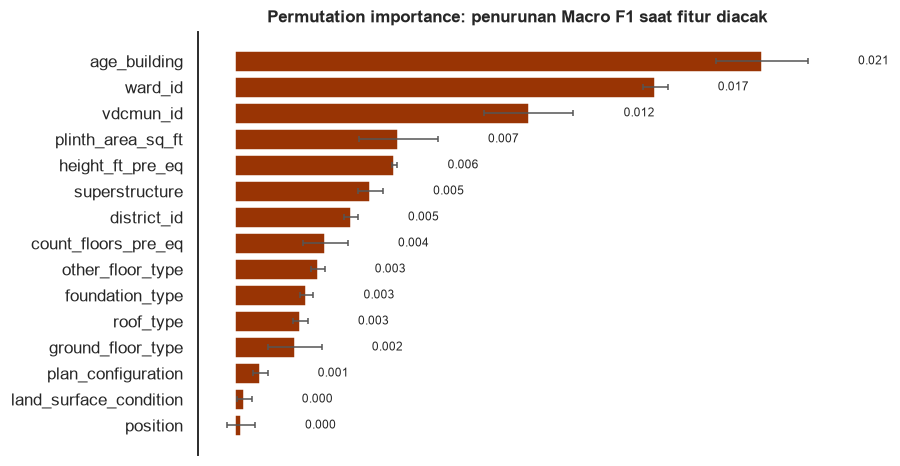

In [11]:
n_perm = min(20_000, len(X_hold))
X_perm = X_hold.sample(n_perm, random_state=SEED)
y_perm = y_hold.loc[X_perm.index]

perm = permutation_importance(holdout_model, X_perm, y_perm, scoring="f1_macro",
                              n_repeats=3, random_state=SEED, n_jobs=1)
importance = (pd.DataFrame({"fitur": X_perm.columns,
                            "penurunan_macro_f1": perm.importances_mean,
                            "std": perm.importances_std})
              .query("fitur != 'building_id'")   # identifier; dibuang oleh DataCleaner
              .sort_values("penurunan_macro_f1"))

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.barh(importance["fitur"], importance["penurunan_macro_f1"], xerr=importance["std"],
        color="#993404", error_kw={"ecolor": "#555555", "lw": 1, "capsize": 2})
for i, (v, s) in enumerate(zip(importance["penurunan_macro_f1"], importance["std"])):
    ax.text(max(v, 0) + s + 0.002, i, f"{v:.3f}", va="center", fontsize=8)
ax.set_xticks([])
ax.spines["bottom"].set_visible(False)
ax.set_title("Permutation importance: penurunan Macro F1 saat fitur diacak")
save_fig("09_permutation_importance")
plt.show()

Bandingkan peringkat ini dengan peringkat χ²/df pada notebook 01. Kesesuaian kedua peringkat memperkuat kesimpulan bahwa fitur tersebut memang penting, sedangkan perbedaan yang mencolok menunjukkan bahwa asosiasi marginal tidak sama dengan kontribusi pada model (misalnya karena fitur tersebut tumpang tindih dengan fitur lain). Perlu diperhatikan pula bahwa kode wilayah bersifat hierarkis (`ward_id` memuat `vdcmun_id`, yang memuat `district_id`), sehingga pada *encoding* ordinal urutan kode mencerminkan kedekatan geografis, hal ini dapat menjelaskan tingginya kepentingan kolom wilayah pada model berbasis pohon. Karena jenis-jenis konstruksi (fondasi, atap, lantai, superstruktur) saling berkorelasi, kepentingannya terbagi di antara kolom-kolom tersebut sehingga masing-masing tampak kecil, pengujian gabungan (mengacak seluruh kolom konstruksi sekaligus) diperlukan untuk menilai kepentingan kelompoknya. Fitur dengan penurunan mendekati nol merupakan kandidat penyederhanaan model.

# 9. Pelatihan akhir dan penyimpanan model
Model akhir dilatih pada **seluruh data latih** (100%), menggunakan fungsi `train_and_save` dari `scripts/train.py`. Dengan demikian, alur yang dijalankan di notebook identik dengan alur yang dijalankan dari terminal:

```bash
python -m scripts.train --params-file models/best_params.json
```

Berkas yang dihasilkan:
- `models/pipeline_model_<nama_model>.pkl`: pipeline lengkap (preprocessing dan model) sehingga dapat dipakai langsung untuk prediksi tanpa pelatihan ulang.
- `models/pipeline_model_<nama_model>_meta.json`: catatan parameter, versi pustaka, dan waktu pelatihan.

Ukuran berkas dicetak setelah penyimpanan. Berkas di atas 100 MB tidak dapat di-*commit* ke GitHub; apabila hal itu terjadi, kurangi kapasitas model (misalnya jumlah pohon atau `min_samples_leaf`) atau pilih model yang lebih kecil dan setara performanya.

Model linear baseline dapat disimpan dengan `python -m scripts.train --model reglog`, yang menghasilkan `models/pipeline_model_reglog.pkl`.

In [12]:
final_model, model_path = train_and_save(
    best_name, data_dir=DATA_DIR, output_dir=MODELS_DIR,
    params=final_params, cv_result=chosen_result, n_jobs=-1)
print("Model tersimpan di:", model_path)
print(f"Ukuran berkas      : {model_path.stat().st_size / 1e6:,.1f} MB")

# Verifikasi: model yang dimuat ulang harus menghasilkan prediksi identik.
# Prediksi acuan dihitung lebih dulu, lalu model di memori dilepas sebelum memuat ulang agar kebutuhan memori tidak berlipat ganda.
check_rows = X_hold.head(1_000)
expected = final_model.predict(check_rows)
del final_model, holdout_model
gc.collect()

try:
    reloaded = load_model(model_path)
    assert (reloaded.predict(check_rows) == expected).all()
    print("Model dimuat ulang dan menghasilkan prediksi yang identik.")
except MemoryError:
    print("Verifikasi dilewati: memori tidak cukup untuk memuat ulang model. "
          "Berkas tersimpan, tetapi model sebesar ini perlu diperkecil (lihat catatan di atas).")

Model tersimpan di: ..\models\pipeline_model_hist_gb_nbr.pkl
Ukuran berkas      : 13.5 MB
Model dimuat ulang dan menghasilkan prediksi yang identik.


# 10. Ringkasan dan kesimpulan

In [13]:
print(f"Model terpilih            : {MODEL_SPECS[best_name].label} ({best_name})")
print(f"Hiperparameter            : {final_params or 'bawaan'}")
print(f"Macro F1 validasi silang  : {chosen_result['macro_f1_mean']:.4f} (± {chosen_result['macro_f1_std']:.4f})")
print(f"Macro F1 hold-out         : {holdout_f1:.4f}")
print(f"Macro F1 baseline mayoritas: {baseline_f1:.4f}")
print(f"Berkas model              : {model_path}")

Model terpilih            : HistGradientBoosting + fitur tetangga ID (hist_gb_nbr)
Hiperparameter            : bawaan
Macro F1 validasi silang  : 0.5128 (± 0.0060)
Macro F1 hold-out         : 0.5758
Macro F1 baseline mayoritas: 0.1063
Berkas model              : ..\models\pipeline_model_hist_gb_nbr.pkl


## Interpretasi
Skor Macro F1 hold-out merupakan estimasi terbaik performa model pada data baru dari populasi yang sama; skor sesungguhnya akan terlihat pada *public* dan *private leaderboard* Kaggle. Skor hold-out dapat lebih tinggi daripada skor validasi silang karena model hold-out dilatih pada data yang jauh lebih banyak (80% data latih) dibandingkan setiap *fold* validasi silang (bagian dari subsampel pengembangan). Selisih ke arah ini menunjukkan bahwa penambahan data meningkatkan performa, dan bukan tanda *overfitting*. Sebaliknya, skor hold-out yang jauh **lebih rendah** daripada skor validasi silang menandakan *overfitting* terhadap proses pemilihan model.

## Implikasi bagi manajemen
Model dapat dipakai untuk memprioritaskan inspeksi dan alokasi dana rekonstruksi: bangunan yang diprediksi berada pada grade kerusakan tinggi diperiksa lebih dahulu. Apabila sebagian besar kesalahan prediksi ternyata bersifat antar-grade bersebelahan (lihat proporsi pada bagian 7), model lebih andal untuk **pemeringkatan prioritas** daripada untuk menetapkan grade kerusakan yang pasti pada setiap bangunan; apabila proporsi tersebut rendah, penggunaan model sebagai alat prioritas perlu disertai kehati-hatian.

## Limitasi dan risiko
- **Eksperimen memakai subsampel.** Perbandingan model dan penyetelan hiperparameter dilakukan pada `SAMPLE_SIZE` baris; peringkat model dapat berubah pada data penuh, terutama untuk model berkapasitas tinggi seperti *gradient boosting*.
- **Hold-out masih memuat baris kembar.** Duplikat fitur dapat membuat skor hold-out sedikit lebih optimistis daripada skor pada data uji.
- **Bobot kelas seimbang bukan pengoptimal Macro F1.** Penyesuaian ambang keputusan atau probabilitas prior per kelas dapat dicoba sebagai perbaikan lanjutan.
- **Struktur ordinal target belum dimanfaatkan.** Model memperlakukan Grade 1–5 sebagai kelas nominal; pendekatan ordinal dapat dicoba sebagai eksperimen tambahan.
- **Encoding Ordinal untuk model pohon bersifat arbitrer**, terutama pada `ward_id` yang memiliki 945 level.
- **Berkas `.pkl` terikat pada versi pustaka.** Muat model hanya dari sumber tepercaya dan gunakan versi scikit-learn yang sama dengan yang tercatat pada berkas meta.

## Langkah berikutnya
Menyusun `scripts/predict.py` dan `notebooks/03_submission.ipynb` untuk menghasilkan `submissions/submission.csv` dari model tersimpan, kemudian mengunggahnya ke Kaggle.